In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(r"C:\Users\Nam\Desktop\Palma")
RVFUNCS_DIR = PROJECT_DIR / "Spectral-toolkit-main"
# Set RVFUNCS_DIR = PROJECT_DIR if your authoritative rvfuncs.py is in Palma.
# This path is needed for legacy fits, without executing the RV notebook.
for directory in reversed([RVFUNCS_DIR, PROJECT_DIR]):
    location = str(directory)
    if location in sys.path:
        sys.path.remove(location)
    sys.path.insert(0, location)

import sb23
import hd195592_common

print("sb23:", sb23.__file__)
print("common:", hd195592_common.__file__)

sb23: C:\Users\Nam\Desktop\Palma\sb23.py
common: C:\Users\Nam\Desktop\Palma\hd195592_common.py


In [ ]:
MODEL_DIR = PROJECT_DIR / "Shenar" / "Models"
POWR_DIR = PROJECT_DIR
SPECTRA_DIR = PROJECT_DIR / "spectra"

MODEL_SPECS = [
    ("B: 15 kK, log g 3.00, rotation 25",
     MODEL_DIR / "BG15000g300v2.vis.rectvmac30vsini25.dat", "shenar"),
    ("B: 20 kK, log g 3.00, rotation 300",
     MODEL_DIR / "BG20000g300v2.vis.rectvmac30vsini300.dat", "shenar"),
    ("B: 27 kK, log g 4.25, rotation 25",
     MODEL_DIR / "BG27000g425v2.vis.rectvmac30vsini25.dat", "shenar"),
    ("O: 35 kK, log g 4.00, rotation 100",
     MODEL_DIR / "G35000g400v10.vis.recvmac30vsini100.dat", "shenar"),
    ("O: 40 kK, log g 4.00, rotation 200",
     MODEL_DIR / "G40000g400v10.vis.rectvmac30vsini200.dat", "shenar"),
    ("PoWR 28-30", POWR_DIR / "ob-i_28-30_line.txt", "powr"),
    ("PoWR 28-32", POWR_DIR / "ob-i_28-32_line.txt", "powr"),
    ("PoWR 30-32", POWR_DIR / "ob-i_30-32_line.txt", "powr"),
]

OBS_FILES = {
    "E05": "20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits",
    "E13": "20261012_01186141_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits",
}

# Configured AIR reference wavelengths from the original comparison.
LINES = [
    ("He I 5016", 5015.678, (4990.0, 5045.0)),
    ("He I 6678", 6678.149, (6645.0, 6710.0)),
]

EW_LINES = {name: rest for name, rest, window in LINES}

VELOCITY_LIMITS = (-400.0, 400.0)
TEMPLATE_WAVELENGTH_SYSTEM = "unknown"
OBS_WAVELENGTH_SYSTEM = "unknown"
POWR_WAVE_FORMAT = "auto"
# auto is numerical inference, not verification of PoWR documentation.

# Illustrative alternatives, NOT optimized RVs or measured light fractions.
TEMPLATE_RV_KMS = 0.0
LIGHT_FRACTION = 1.0
RV_BY_FILE = {}
LIGHT_FRACTION_BY_FILE = {}

In [ ]:
# %% CELL 3 — Read models and observations through the module

models, model_failures = sb23.load_templates(
    MODEL_SPECS,
    powr_wave_format=POWR_WAVE_FORMAT,
    verbose=True,
)
if not models:
    raise RuntimeError("No templates loaded; check paths and filenames.")

if model_failures:
    print("Templates not loaded:")
    display(pd.DataFrame(model_failures))

model_datasets = {model["label"]: model for model in models}
model_table = pd.DataFrame([
    {
        "label": model["label"],
        "file": model["filename"],
        "kind": model["kind"],
        "n_samples": len(model["wave"]),
        "wave_min_A": model["wave"][0],
        "wave_max_A": model["wave"][-1],
    }
    for model in models
])
display(model_table)

observations, observation_failures = sb23.load_observations(
    SPECTRA_DIR,
    OBS_FILES,
    reader=sb23.read_hermes_inspection,
)
if observation_failures:
    print("Observations not loaded:")
    display(pd.DataFrame(observation_failures))
if not observations:
    print("No observations loaded; template-only inspection remains possible.")

sb23.check_wavelength_systems(
    TEMPLATE_WAVELENGTH_SYSTEM,
    OBS_WAVELENGTH_SYSTEM,
    reference_system="air",
)

ob-i_28-30_line.txt: numerically inferred angstrom; verify documentation.
ob-i_28-32_line.txt: numerically inferred angstrom; verify documentation.
ob-i_30-32_line.txt: numerically inferred angstrom; verify documentation.


,label,file,kind,n_samples,wave_min_A,wave_max_A
0,"B: 15 kK, log g 3.00, rotation 25",BG15000g300v2.vis.rectvmac30vsini25.dat,shenar,317039,3200.00011,9999.00670
1,"B: 20 kK, log g 3.00, rotation 300",BG20000g300v2.vis.rectvmac30vsini300.dat,shenar,315687,3200.00011,9998.98839
2,"B: 27 kK, log g 4.25, rotation 25",BG27000g425v2.vis.rectvmac30vsini25.dat,shenar,311019,3200.00011,9998.93824
3,"O: 35 kK, log g 4.00, rotation 100",G35000g400v10.vis.recvmac30vsini100.dat,shenar,197328,3000.00000,7498.33900
4,"O: 40 kK, log g 4.00, rotation 200",G40000g400v10.vis.rectvmac30vsini200.dat,shenar,196436,3000.00000,7498.33000
5,PoWR 28-30,ob-i_28-30_line.txt,powr,81486,3099.10000,9996.86300
6,PoWR 28-32,ob-i_28-32_line.txt,powr,81489,3099.10000,9996.93900
7,PoWR 30-32,ob-i_30-32_line.txt,powr,81260,3099.10000,9996.97100


20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits: removed 478; averaged 0 duplicates; originally sorted=True
20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits: CTYPE1='log(wavelength)', CUNIT1='unspecified', CRPIX1=1.0, BJD=2461321.3232428
20261012_01186141_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits: removed 478; averaged 0 duplicates; originally sorted=True
20261012_01186141_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits: CTYPE1='log(wavelength)', CUNIT1='unspecified', CRPIX1=1.0, BJD=2461326.5087738


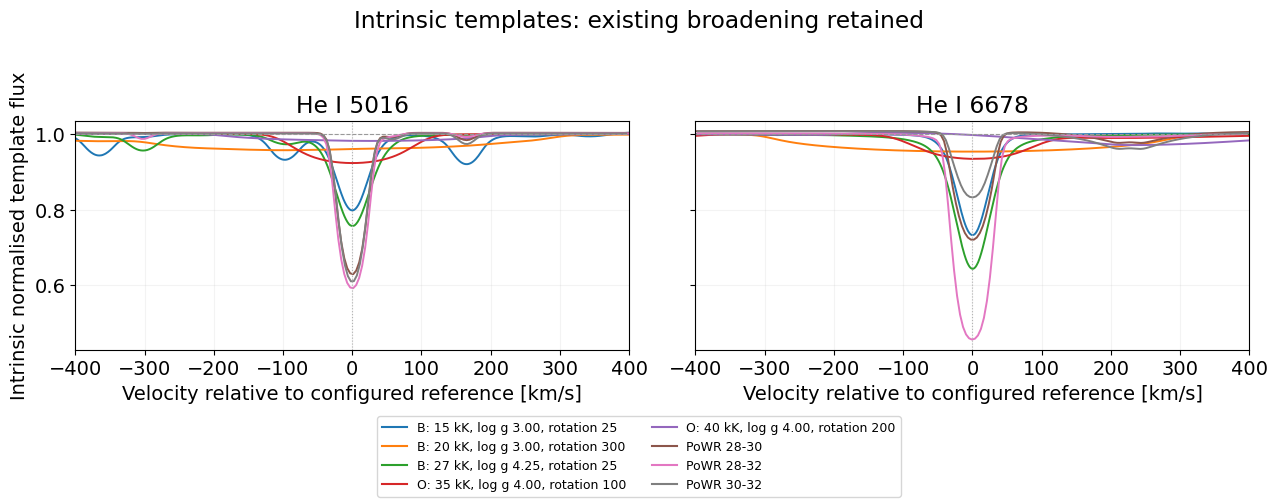

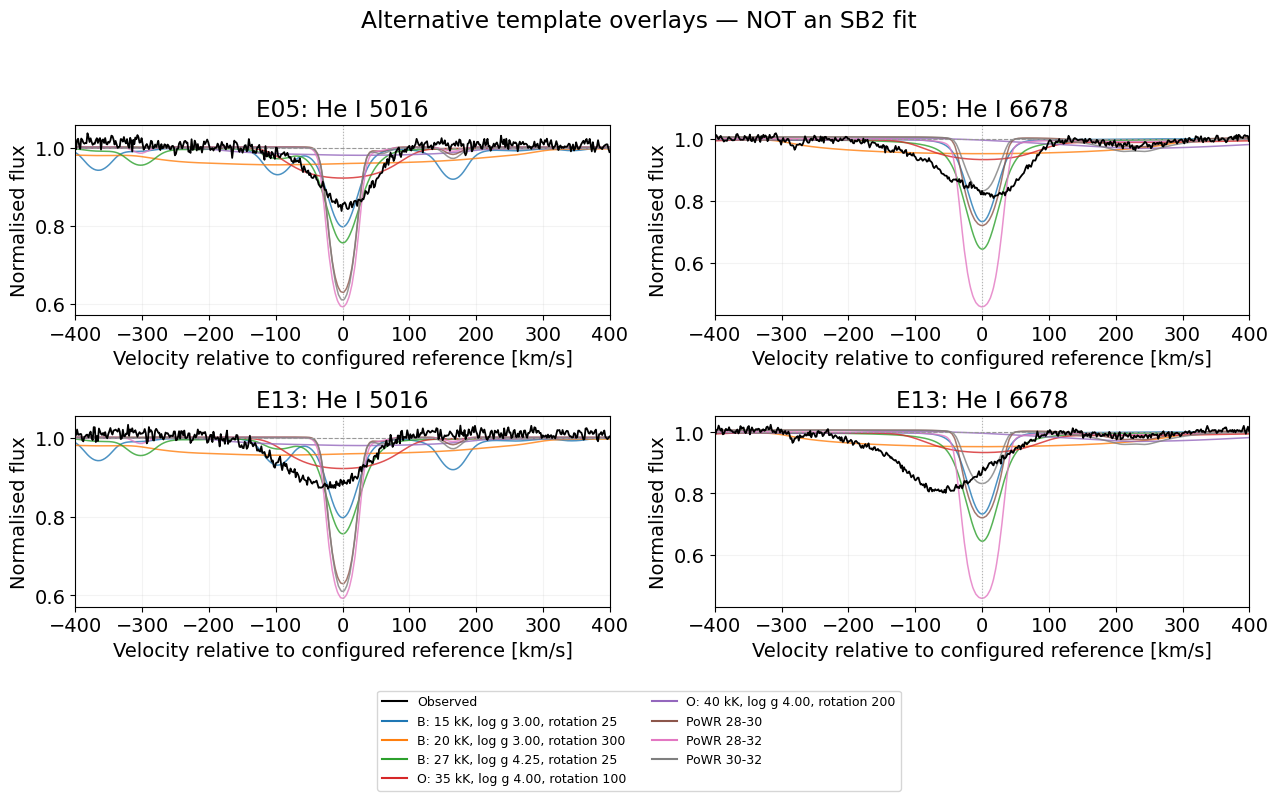

Each coloured curve is an alternative single-template contribution.
No template RV, light fraction, broadening or binary fit was optimized.


In [5]:
# %% CELL 4 — Intrinsic profiles and illustrative template overlays
# Two different displays: intrinsic models, then their contributions on data.
# No new broadening, template optimization or SB2/SB3 template sum.

fig_intrinsic = sb23.plot_template_profiles(
    models,
    LINES,
    velocity_limits=VELOCITY_LIMITS,
)
plt.show()

fig_comparison = None
if observations:
    fig_comparison = sb23.plot_template_comparison(
        models,
        observations,
        LINES,
        velocity_limits=VELOCITY_LIMITS,
        rv_kms=TEMPLATE_RV_KMS,
        light_fraction=LIGHT_FRACTION,
        rv_by_file=RV_BY_FILE,
        fraction_by_file=LIGHT_FRACTION_BY_FILE,
    )
    plt.show()

print("Each coloured curve is an alternative single-template contribution.")
print("No template RV, light fraction, broadening or binary fit was optimized.")

In [6]:
# %% CELL 5 — One common EW configuration
# Replaces the repeated PoWR-only and combined-model EW diagnostic blocks.

EW_CONFIG = sb23.EWConfig(
    integration_range=(-220.0, 120.0),
    continuum_ranges=((-390.0, -320.0), (330.0, 390.0)),
    test_ranges=((-180.0, 100.0), (-220.0, 120.0), (-260.0, 140.0)),
    neighbourhood=(-450.0, 450.0),
    plot_range=VELOCITY_LIMITS,
    clip_sigma=3.0,
    min_side_pixels=8,
)

# Explicit selection-window offsets, not fitted RVs.
EW_WINDOW_OFFSETS_KMS = {}

In [ ]:
# %% CELL 6 — Measure EWs once and display the result tables

EW_DATASETS = dict(model_datasets)
EW_DATASETS.update(observations)

EW_RESULTS, EW_PROFILES, EW_FAILURES = sb23.screen_ews(
    EW_DATASETS,
    EW_LINES,
    EW_CONFIG,
    offsets_kms=EW_WINDOW_OFFSETS_KMS,
    verbose=True,
)
if EW_FAILURES:
    print("EW measurements unavailable:")
    display(pd.DataFrame(EW_FAILURES))

EW_TABLE = sb23.ew_table(
    EW_RESULTS,
    "He I 5016",
    "He I 6678",
).rename(columns={
    "first_EW_A": "W5016_A",
    "first_error_A": "W5016_formal_error_A",
    "second_EW_A": "W6678_A",
    "second_error_A": "W6678_formal_error_A",
    "ratio": "W5016_over_W6678",
})
display(EW_TABLE)

EW_TEMPLATE_RATIOS = sb23.observed_template_ratios(
    EW_RESULTS,
    EW_DATASETS,
    EW_LINES,
)
display(EW_TEMPLATE_RATIOS)

print("EWs are finite-window measurements, not assured isolated-line totals.")
print("Formal errors omit correlated noise, blends and systematic continuum errors.")
print("Observed/template EW ratios are NOT measured light fractions.")

CAUTION: B: 15 kK, log g 3.00, rotation 25, He I 5016: >10% EW sensitivity to integration limits.
CAUTION: B: 20 kK, log g 3.00, rotation 300, He I 5016: >10% EW sensitivity to integration limits.
CAUTION: B: 20 kK, log g 3.00, rotation 300, He I 6678: >10% EW sensitivity to integration limits.
CAUTION: O: 40 kK, log g 4.00, rotation 200, He I 5016: >10% EW sensitivity to integration limits.


,spectrum,W5016_A,W5016_formal_error_A,W6678_A,W6678_formal_error_A,W5016_over_W6678,ratio_error
0,"B: 15 kK, log g 3.00, rotation 25",0.074298,NaN,0.343798,NaN,0.216109,NaN
1,"B: 20 kK, log g 3.00, rotation 300",0.161987,NaN,0.321468,NaN,0.503899,NaN
2,"B: 27 kK, log g 4.25, rotation 25",0.271343,NaN,0.570804,NaN,0.475369,NaN
3,"O: 35 kK, log g 4.00, rotation 100",0.206351,NaN,0.224510,NaN,0.919118,NaN
4,"O: 40 kK, log g 4.00, rotation 200",0.080222,NaN,-0.053749,NaN,NaN,NaN
5,PoWR 28-30,0.289482,NaN,0.350139,NaN,0.826763,NaN
6,PoWR 28-32,0.340853,NaN,0.758164,NaN,0.449577,NaN
7,PoWR 30-32,0.295388,NaN,0.194493,NaN,1.518758,NaN
8,E05,0.314948,0.006284,0.606952,0.007083,0.518901,0.011995
9,E13,0.329988,0.006924,0.736392,0.005076,0.448115,0.009897


,epoch,template,line,observed_over_template
0,E05,"B: 15 kK, log g 3.00, rotation 25",He I 5016,4.238996
1,E05,"B: 15 kK, log g 3.00, rotation 25",He I 6678,1.765432
2,E05,"B: 20 kK, log g 3.00, rotation 300",He I 5016,1.944273
3,E05,"B: 20 kK, log g 3.00, rotation 300",He I 6678,1.888064
4,E05,"B: 27 kK, log g 4.25, rotation 25",He I 5016,1.160701
5,E05,"B: 27 kK, log g 4.25, rotation 25",He I 6678,1.063328
6,E05,"O: 35 kK, log g 4.00, rotation 100",He I 5016,1.526272
7,E05,"O: 35 kK, log g 4.00, rotation 100",He I 6678,2.703454
8,E05,"O: 40 kK, log g 4.00, rotation 200",He I 5016,3.925970
9,E05,PoWR 28-30,He I 5016,1.087971


EWs are finite-window measurements, not assured isolated-line totals.
Formal errors omit correlated noise, blends and systematic continuum errors.
Observed/template EW ratios are NOT measured light fractions.


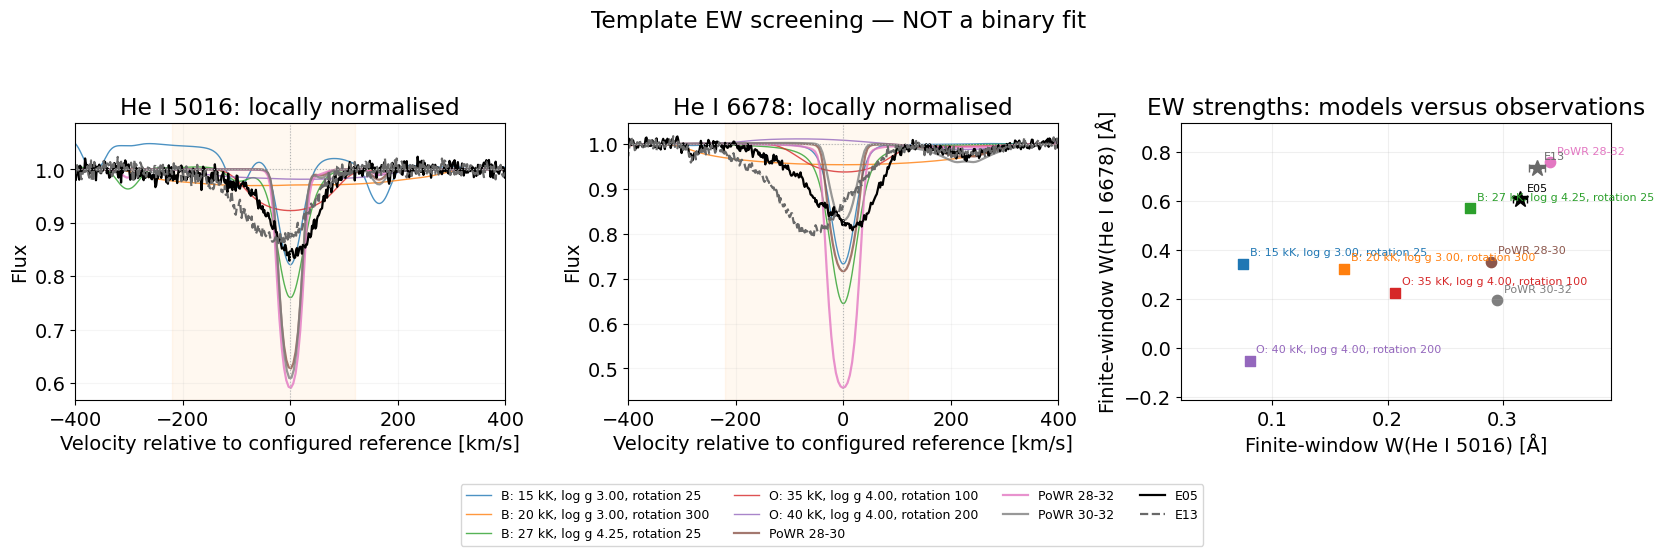

In [ ]:
# %% CELL 7 — One EW summary figure
# Do not repeat plot_ew_diagnostics() or the old separate EW measurement cells.

fig_ew = sb23.plot_ew_screen(
    EW_DATASETS,
    EW_PROFILES,
    EW_RESULTS,
    EW_LINES,
    EW_CONFIG,
)
plt.show()

In [11]:

# %% CELL 8 — Optional legacy joint-He experiment: settings
# The earlier per-line shared-shape 2G/3G test is not run again here.
# Profile-registration diagnostics remain in rvanalysis.ipynb.

RUN_LEGACY_JOINT_HE = True
LEGACY_TRAIN = ["E05", "E13"]
LEGACY_VALIDATE = ["E08", "E10", "E11"]
LEGACY_LINES = {
    "He I 6678": 6678.149,
    "He I 5016": 5015.678,
}
LEGACY_COMPONENT_COUNTS = (2, 3)

LEGACY_GAUSSIAN_CONFIG = sb23.LegacyGaussianConfig(
    local_continuum=False,
    gauss_fit_half=160.0,
    fit_half=300.0,
    rv_range=200.0,
    cont_bounds=(240.0, 340.0),
    search_half=200.0,
    additional_shift_kms=0.0,
    n_starts=36,
    seed=35,
)
LEGACY_JOINT_CONFIG = sb23.LegacyJointConfig(
    train_starts=36,
    epoch_starts=24,
    max_nfev=6000,
    seed=351026,
    sigma_bounds=(8.0, 150.0),
    depth_max=0.95,
    cont_offset=0.04,
    cont_tilt=0.04,
    near_delta=10.0,
    max_train_branches=3,
    mode_distance=1.0,
    match_rv=15.0,
    match_sigma=10.0,
    match_depth=0.025,
    core_half=150.0,
    core_rms_limit=1.3,
    core_degradation=0.15,
    rv_span_limit=25.0,
    bound_fraction=0.001,
)



Legacy Gaussian dependency: C:\Users\Nam\Desktop\Palma\Spectral-toolkit-main\rvfuncs.py


epoch          BJD                                                                 file
  E05 2.461321e+06 20261007_01185612_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E13 2.461327e+06 20261012_01186141_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E08 2.461324e+06 20261010_01185892_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E10 2.461325e+06 20261011_01186002_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
  E11 2.461325e+06 20261011_01186014_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf_norm.fits
LEGACY: LOCAL_CONTINUUM=False; explicit shift=0.0 km/s
2G: converged 36/36; near TRAIN modes=1; validating 1 branches.
2G branch 1, E08: joint + independent comparison...
2G branch 1, E10: joint + independent comparison...
2G branch 1, E11: joint + independent comparison...
3G: converged 36/36; near TRAIN modes=2; validating 2 branches.
3G branch 1, E08: joint + independent comparison...
3G branch 1, E10: joint + independent comparison...
3G branch 1, E11: joint + ind

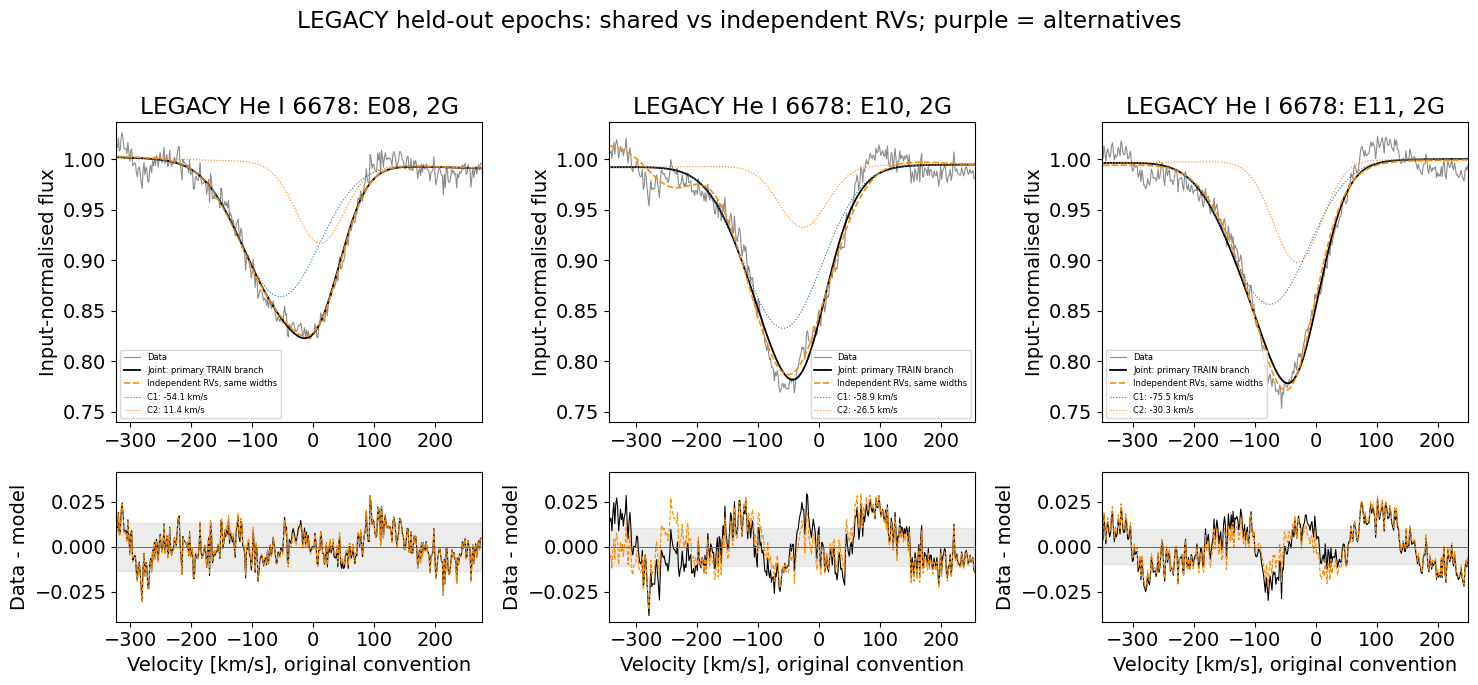

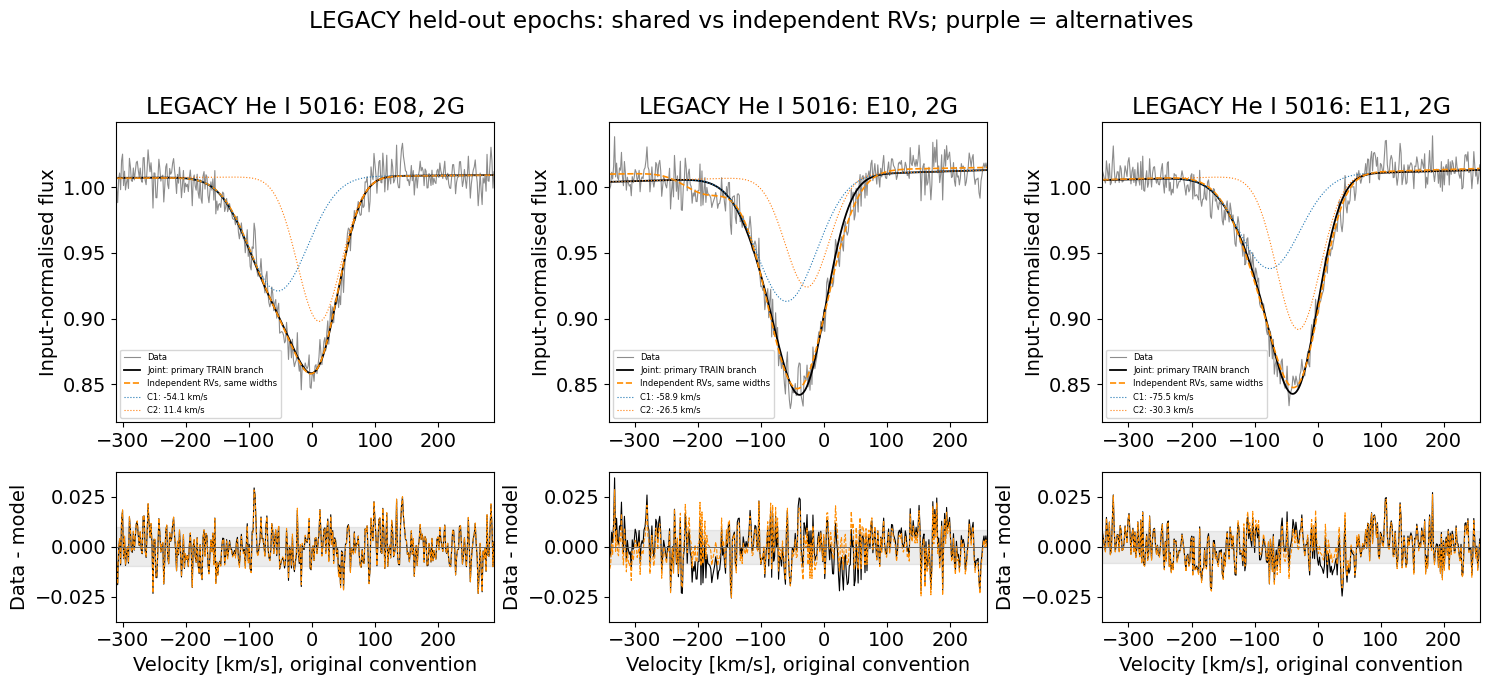

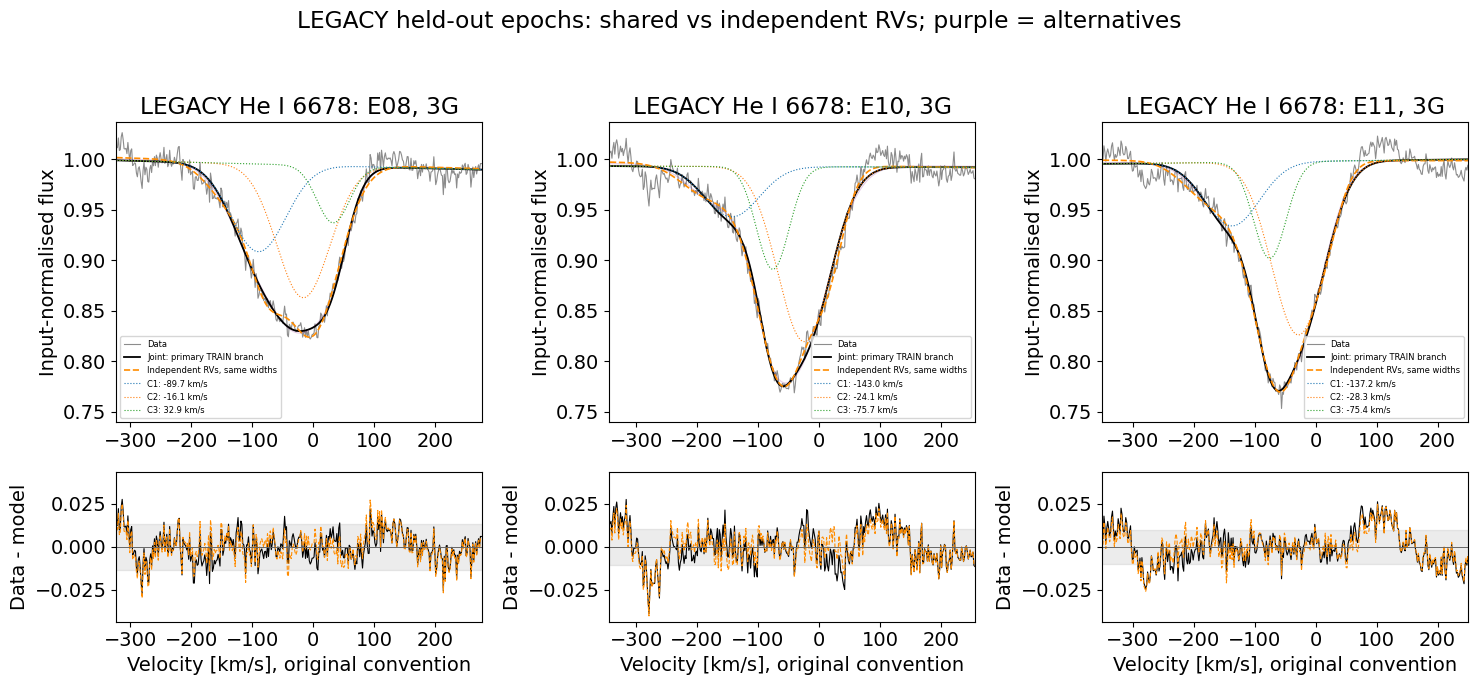

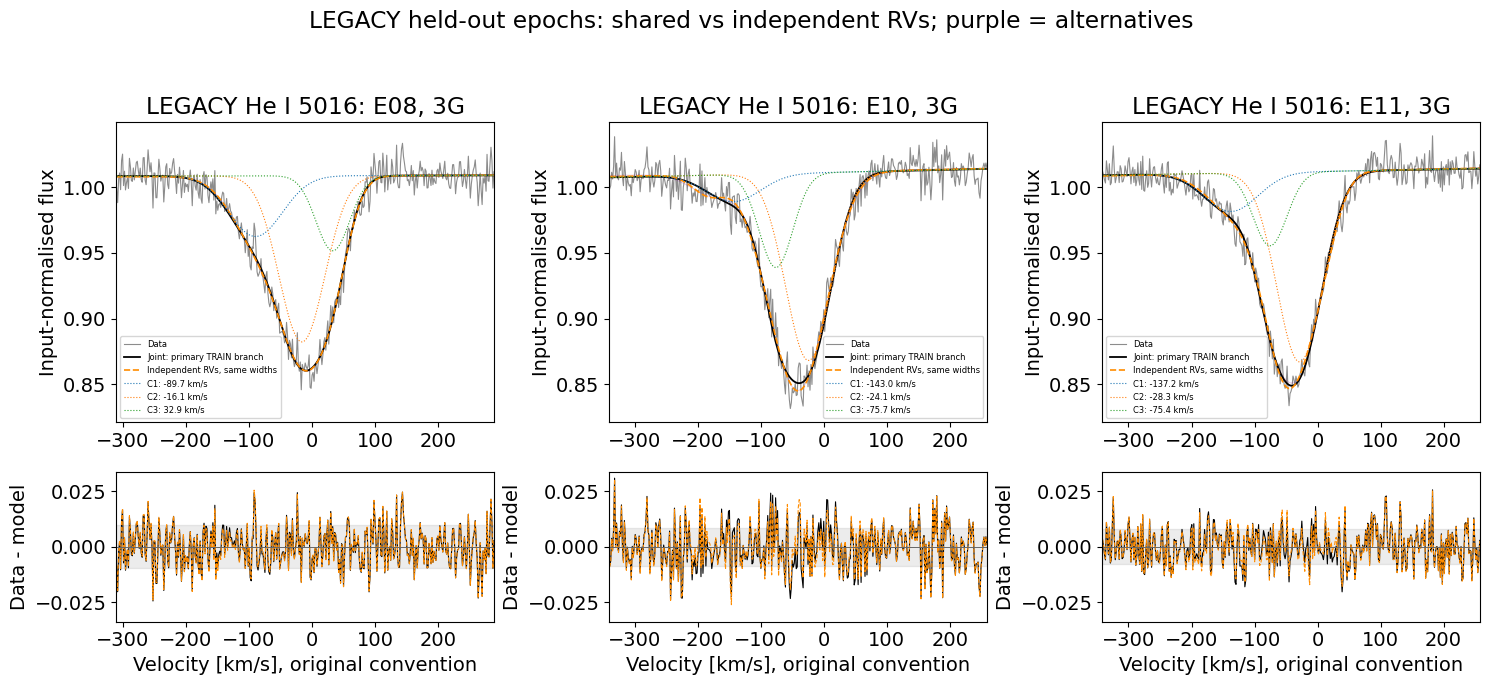

Legacy results retained in LEGACY_JOINT_RESULTS; nothing saved.


In [12]:

# %% CELL 9 — Call the optional legacy joint experiment
# Computationally intensive. Component labels are not established stars.
# The runner prints its tables; avoid displaying the same tables a second time.

LEGACY_JOINT_RESULTS = None
if RUN_LEGACY_JOINT_HE:
    import rvfuncs
    print("Legacy Gaussian dependency:", rvfuncs.__file__)

    legacy_spectra = sb23.load_spectra(
        SPECTRA_DIR,
        pattern="*.fits",
    )
    LEGACY_JOINT_RESULTS = sb23.run_legacy_joint_he(
        legacy_spectra,
        LEGACY_LINES,
        LEGACY_TRAIN,
        LEGACY_VALIDATE,
        LEGACY_COMPONENT_COUNTS,
        LEGACY_GAUSSIAN_CONFIG,
        LEGACY_JOINT_CONFIG,
        make_plots=True,
        verbose=True,
    )
    plt.show()
    print("Legacy results retained in LEGACY_JOINT_RESULTS; nothing saved.")
else:
    print("Legacy joint 2G/3G experiment skipped.")
    print("Set RUN_LEGACY_JOINT_HE=True to run it.")
